---
title: "L4-09 · Counterfactual reasoning"
short_title: "Counterfactual reasoning"
subtitle: "A counterfactual keeps the background factors of the unit you actually observed and changes one mechanism, so it can say more about that unit than any population average, but only as much as the structural model can be trusted."
description: "Use abduction, action, and prediction to compute a counterfactual in an explicit structural causal model, and explain why such answers need more than interventional data."
tags: [level-4, coursebook]
---

(lesson-l4-09)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 90 minutes  
**Big idea.** A counterfactual keeps the background factors of the unit you actually observed and changes one mechanism, so it can say more about that unit than any population average, but only as much as the structural model can be trusted.  
**Before this lesson.** [L4-01](#lesson-l4-01), [L4-06](#lesson-l4-06), [L4-07](#lesson-l4-07)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Carry out abduction, action, and prediction in a structural causal model and report the counterfactual value for an observed unit.
- Distinguish $E[Y \mid X = x]$, $E[Y \mid do(X = x)]$, and a unit's counterfactual $Y_x(u)$, and compute all three in a linear Gaussian model.
- Compute a counterfactual distribution when the evidence only partly determines the background variables.
- Show with two explicit models that interventional data do not fix counterfactuals, and compute the bounds on the probability of necessity when the treatment is randomized.

## Why this matters

A student joined a tutoring program ($X = 1$) and scored $Y = 5$ on a test scale. Would the score have been lower without the program? A randomized trial can tell you how the average score of a population would change if everyone, or nobody, joined. It cannot by itself tell you about this student, whom you have already observed. The question mixes a fact (what happened) with a supposition that contradicts the fact (the program not taken), and the answer has to respect both.

Questions of this kind are everywhere: responsibility (would the outage have happened without that software update?), medicine (was the drug the reason this patient recovered?), and machine learning (what is the smallest change to this application that would have changed the decision?). The structural causal models of [L4-01](#lesson-l4-01) answer them with a definite three-step procedure [@pearl; @pearlcausality]. The price is that the answer depends on details of the mechanisms that even perfect experiments may not reveal. This lesson computes counterfactuals and shows exactly where that dependence enters.

:::{dropdown} Key terms

**Counterfactual**
: A statement about what $Y$ would have been for the same unit had $X$ been $x$, written $Y_x$, evaluated given what was actually observed.

**Abduction**
: Updating the distribution of the background variables $U$ from $P(u)$ to $P(u \mid e)$ using the factual evidence $e$.

**Action (surgery)**
: Replacing the mechanism of $X$ by the constant assignment $X := x$, which deletes every arrow into $X$.

**Prediction**
: Computing $Y$ in the edited model with the background distribution produced by abduction.

**Potential response**
: $Y_x(u)$: the value the edited model $M_x$ gives $Y$ when the background variables equal $u$.

**Probability of necessity**
: $\mathrm{PN} = P(Y_{x'} = y' \mid X = x, Y = y)$: among units with treatment and outcome, the share whose outcome would have been absent without treatment.

**Twin network**
: A graph that draws the factual and the counterfactual world side by side, sharing the same background variables.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_09 as _lessonfigs

## The third rung: from doing to imagining

Pearl organizes causal questions on three rungs [@pearl; @bareinboim]. **Seeing**: $P(y \mid x)$, what we expect to observe among units with $X = x$. **Doing**: $P(y \mid do(x))$, what would happen in the population if we set $X$ to $x$ ([L4-01](#lesson-l4-01), [L4-06](#lesson-l4-06)). **Imagining**: $P(Y_{x'} = y' \mid X = x, Y = y)$, what would have happened to units we saw with $X = x$ and $Y = y$, had $X$ been $x'$. The third rung conditions on facts and then contradicts one of them, so it needs a model that links the actual world to the imagined one.

:::{prf:definition} Structural causal model, submodel, potential response
:label: def-l4-09-scm
A **structural causal model** $M$ has background (exogenous) variables $U$ with a distribution $P(u)$, modeled (endogenous) variables $V$, and one mechanism $V_i := f_i(\mathrm{pa}_i, u_i)$ for each $V_i$, where $\mathrm{pa}_i \subseteq V$ are its direct causes and the graph is acyclic. For an action $do(X = x)$ the **submodel** $M_x$ replaces the mechanism of $X$ by $X := x$ and keeps all other mechanisms and $P(u)$. The **potential response** $Y_x(u)$ is the value of $Y$ that $M_x$ produces when $U = u$. Because the graph is acyclic, every $u$ gives exactly one solution.
:::

The running model of this lesson gives each variable its own background input:

$$
X := U_X, \qquad Y := 2X + U_Y, \qquad U_X \sim \mathcal{N}(0, 1),\ \ U_Y \sim \mathcal{N}(1, 1) \text{ independent}
$$ (eq-l4-09-scm)

In [](#eq-l4-09-scm) the background variables are independent, so there is no confounding: $E[Y \mid X = x] = E[Y \mid do(X = x)] = 2x + 1$. (The model of [L4-01](#lesson-l4-01) used one shared $U$ for both equations; here $U_X$ and $U_Y$ are separate, which is what lets us see $X = 1$ together with $Y = 5$.) Every unit has the same effect, $Y_1(u) - Y_0(u) = 2$, because $U_Y$ cancels. Even so, the question about one observed unit is not answered by $E[Y \mid do(X = 0)] = 1$.

:::{prf:definition} Counterfactual given evidence
:label: def-l4-09-cf
Let $e$ be evidence, an observed value of some endogenous variables, with $P(e) > 0$. The **counterfactual distribution** of $Y$ under $do(X = x)$ given $e$ is [](#eq-l4-09-cf). Read it as: the probability that $Y$ would have been $y$ had $X$ been $x$, for the units in which we saw $e$. For continuous $U$ the sum is an integral.
:::

$$
P(Y_x = y \mid e) = \sum_{u} \mathbf{1}\left[\,Y_x(u) = y\,\right] P(u \mid e)
$$ (eq-l4-09-cf)

## Abduction, action, prediction

:::{prf:theorem} Three-step evaluation of counterfactuals
:label: thm-l4-09-three-steps
Given a structural model $M$, evidence $e$ with $P(e) > 0$, and an action $do(X = x)$, the distribution $P(Y_x = y \mid e)$ of [](#eq-l4-09-cf) is obtained by: (1) **abduction**, replacing $P(u)$ by $P(u \mid e)$, computed in the original model $M$; (2) **action**, forming the submodel $M_x$; (3) **prediction**, computing the distribution of $Y$ in $M_x$ when $U$ has the distribution $P(u \mid e)$ [@pearlcausality].
:::

:::{prf:proof}
In step 3, $Y$ is a function $u \mapsto Y_x(u)$ of the background variables in $M_x$, and $U$ has the law $P(u \mid e)$. So $P(Y = y)$ in step 3 is $\sum_u \mathbf{1}[Y_x(u) = y]\,P(u \mid e)$, which is [](#eq-l4-09-cf). The order matters: the evidence was produced by $M$, not by $M_x$, so abduction must use $M$. Doing abduction in $M_x$ would try to explain the observation $X = 1$ with the mechanism $X := 0$, which is impossible.
:::

:::{figure} ../../_static/animations/l4_09_three_steps.mp4
:alt: A causal graph with U_X to X, X to Y, and U_Y to Y. The evidence X = 1, Y = 5 is used to solve u_Y = 3, the arrow into X is cut and X is set to 0, and the same noise gives Y = 3.
:width: 100%

Abduction recovers the unit's noise $u_Y = 3$; action cuts the arrow into $X$ and sets $X := 0$; prediction gives $Y_{X=0} = 3$.
:::

:::{dropdown} What the animation shows
The graph shows $U_X \to X$, $X \to Y$, $U_Y \to Y$, beside the mechanisms $X := U_X$ and $Y := 2X + U_Y$. The evidence $X = 1$, $Y = 5$ appears under the nodes. Step 1, abduction: the equation $5 = 2 \cdot 1 + u_Y$ transforms into $u_Y = 3$, and the background nodes are labeled $u_X = 1$ and $u_Y = 3$. Step 2, action: the arrow from $U_X$ into $X$ is crossed out and removed, the mechanism $X := U_X$ becomes $X := 0$, and the node $X$ is marked $do(X = 0)$. Step 3, prediction: with the same noise, $Y_{X=0} = 2 \cdot 0 + 3 = 3$. The scene ends with factual 5, counterfactual 3, effect 2 for this unit.
:::

:::{prf:proposition} Additive noise makes abduction exact
:label: prop-l4-09-additive
Suppose $Y := f(\mathrm{pa}_Y) + U_Y$ and the evidence includes $Y = y$ and the parents $\mathrm{pa}_Y = p$. Then $u_Y = y - f(p)$ exactly. If, in the submodel and with the abducted background values, the parents of $Y$ take the value $p'$, the counterfactual is $Y = y + f(p') - f(p)$. For the running model, $f(x) = 2x$ and [](#eq-l4-09-additive) holds.
:::

:::{prf:proof}
From $y = f(p) + u_Y$ we get $u_Y = y - f(p)$, a single value, so abduction puts all its probability there. The action leaves the mechanism of $Y$ and the value $u_Y$ unchanged, so prediction gives $f(p') + u_Y = y + f(p') - f(p)$.
:::

$$
Y_{x'} = y + 2(x' - x), \qquad Y_{X=0} = 5 + 2(0 - 1) = 3
$$ (eq-l4-09-additive)

```{mermaid}
graph TD
  UX(("U_X = 1")) --> X["X = 1 (seen)"]
  X --> Y["Y = 5 (seen)"]
  UY(("U_Y = 3")) --> Y
  Xs["X* := 0 (action)"] --> Ys["Y* = 3 (predicted)"]
  UY --> Ys
```

*A twin network. The factual world (left) and the counterfactual world (right) share the background variable $U_Y$. The starred copy of $X$ has no incoming arrow because the action replaced its mechanism, and the counterfactual $Y^*$ inherits $u_Y = 3$ from the factual world.*

:::{prf:remark} Consistency is a theorem inside a structural model
If the unit actually had $X = x$, then $Y_x(u) = Y(u)$: setting $X$ to the value it already had changes nothing. This is the consistency assumption of [L4-06](#lesson-l4-06). In a structural model it follows from the definitions, because $M$ and $M_x$ give the same solution when the old mechanism already produced $x$.
:::

## A population average is not a unit's counterfactual

Three different numbers answer three different questions about $X = 0$ in the running model. Seeing: $E[Y \mid X = 0] = 1$. Doing: $E[Y \mid do(X = 0)] = 1$, the same here because nothing confounds $X$ and $Y$. Imagining, for the unit seen with $X = 1$ and $Y = 5$: $Y_{X=0} = 3$. The unit's counterfactual is higher than the average because abduction learned that this unit has a large $u_Y$.

Evidence need not pin down $U$. Suppose we saw only $Y = 5$ and not $X$. Then $(u_X, u_Y)$ could be any point on the line $2u_X + u_Y = 5$, and abduction gives a distribution along that line. In this model $Y_{X=0} = U_Y$, so we need the law of $U_Y$ given $Y = 5$. Here $\operatorname{Var}(Y) = 2^2 \cdot 1 + 1 = 5$ and $\operatorname{Cov}(U_Y, Y) = \operatorname{Var}(U_Y) = 1$, and the conditioning formula for jointly Gaussian variables gives

$$
E[U_Y \mid Y = y] = 1 + \frac{\operatorname{Cov}(U_Y, Y)}{\operatorname{Var}(Y)}\,(y - 1) = 1 + \tfrac{1}{5}(y - 1), \qquad \operatorname{Var}(U_Y \mid Y = y) = 1 - \tfrac{1}{5} = \tfrac{4}{5}
$$ (eq-l4-09-posterior)

At $y = 5$, [](#eq-l4-09-posterior) gives $E[U_Y \mid Y=5] = 1 + \tfrac{1}{5}(5-1) = 1.8$, so $Y_{X=0} \mid Y=5 \ \sim\ \mathcal{N}(1.8,\ 0.8)$. More evidence gives a sharper answer: no evidence leaves the interventional law $\mathcal{N}(1, 1)$, the evidence $Y = 5$ gives $\mathcal{N}(1.8,\ 0.8)$, and the evidence $X = 1, Y = 5$ gives the single value $3$.

:::{figure} ../../_static/animations/l4_09_average_vs_unit.mp4
:alt: A bell curve for the value Y would have had at X = 0. It starts centered at 1, shifts and narrows to center 1.8 when Y = 5 is seen, then collapses to a single spike at 3 when X = 1 is also seen.
:width: 100%

The same counterfactual question with growing evidence: $\mathcal{N}(1, 1)$, then $\mathcal{N}(1.8,\ 0.8)$, then the single value 3.
:::

:::{dropdown} What the animation shows
Axes show possible values of $Y_{X=0}$ from $-2$ to $6$. The model $U_X \sim \mathcal{N}(0,1)$, $U_Y \sim \mathcal{N}(1,1)$ is written at the top right. With no evidence the curve is $\mathcal{N}(1, 1)$, labeled $E[Y \mid do(X=0)] = 1$. When $Y = 5$ is seen, the formula $E[U_Y \mid Y=5] = 1 + \tfrac{1}{5}(5-1)$ appears and the curve slides right and narrows into $Y_{X=0} \mid Y=5 \ \sim\ \mathcal{N}(1.8,\ 0.8)$, leaving a faint copy of the first curve. When $X = 1$ is also seen, the curve is replaced by a single spike at 3, labeled $Y_{X=0} = 2 \cdot 0 + 3 = 3$ and one unit, one value. A closing line says the population average under $do(X=0)$ is 1 while this unit's counterfactual is 3.
:::


In [2]:
_show(_lessonfigs.evidence_explorer())

**Explore.** Move the slider to change the observed $Y$ (with $X$ unobserved). Left: the evidence line $2u_X + u_Y = y$ in the plane of background values, with the posterior mean and, as a diamond, the single point left if $X = 1$ is also seen. Right: the law of $Y_{X=0}$ before evidence (dashed), after seeing $Y$ (solid), and the single value when $X = 1$ is also seen (vertical line).

:::{dropdown} What the figure shows
The first panel shows dotted circles of radius 1 and 2 around the prior mean $(0, 1)$ of $(U_X, U_Y)$ and the blue line $u_Y = y - 2u_X$ for the chosen $y$. A blue dot marks the posterior mean $\big(\tfrac{2}{5}(y - 1),\ 1 + \tfrac{1}{5}(y - 1)\big)$ and a cyan diamond marks $(1, y - 2)$. The second panel shows the dashed prior density $\mathcal{N}(1, 1)$, the solid posterior density $\mathcal{N}(1 + (y-1)/5,\ 0.8)$, and a vertical line at $y - 2$. At $y = 5$ the posterior mean is 1.8 and the line is at 3.
:::

:::{important} Conditioning on evidence that the action contradicts
The counterfactual $P(Y_0 \mid X = 1, Y = 5)$ is not $P(Y \mid do(X = 0), X = 1)$; the latter asks about units that have $X = 0$ and $X = 1$ at once and is meaningless. The subscript lives in the imagined world, and the conditioning bar lives in the actual world. Background variables are the bridge between the two.
:::

## What experiments cannot settle

The running model had the same effect for every unit, so the unit's answer followed from the model. Real mechanisms need not be that tidy. When effects vary across units, two models can agree on every experiment you could run and still disagree about an individual counterfactual [@pearlcausality; @peters].

:::{prf:proposition} Interventional data do not determine counterfactuals
:label: prop-l4-09-two-models
Let $U \sim \text{Bernoulli}(1/2)$, let $X$ be a fair coin independent of $U$, and compare model A, $Y := U$, with model B, $Y := X \oplus U$ (exclusive or). The two models have the same observational distribution $P(x, y)$ and the same interventional distributions, $P(Y = 1 \mid do(X = x)) = 1/2$ for $x = 0, 1$. Yet $P(Y_0 = 0 \mid X = 1, Y = 1)$ is 0 in model A and 1 in model B.
:::

:::{prf:proof}
In both models $Y$ is a fair coin independent of $X$: in A because $Y = U$; in B because, for each fixed $x$, $x \oplus U$ is a fair coin. So $P(x, y) = 1/4$ for all four cells in both models, and $P(Y = 1 \mid do(X = x)) = P(Y_x = 1) = 1/2$. For the unit with $X = 1$ and $Y = 1$, abduction gives $u = 1$ in A (since $Y = U$) and $u = 0$ in B (since $1 \oplus u = 1$). Prediction under $X := 0$ gives $Y_0 = u = 1$ in A and $Y_0 = 0 \oplus 0 = 0$ in B.
:::

:::{figure} ../../_static/animations/l4_09_two_models.mp4
:alt: Two small tables of potential outcomes, one for Y := U and one for Y := X xor U. Both give the same averages, but the highlighted unit has Y_0 = 1 in the first model and Y_0 = 0 in the second.
:width: 100%

Model A ($Y := U$): nobody is affected. Model B ($Y := X \oplus U$): everybody is affected, half helped and half harmed. Same experiments, opposite answers about one unit.
:::

:::{dropdown} What the animation shows
Two tables list the potential outcomes $(Y_0, Y_1)$ for $u = 0$ and $u = 1$. Model A, $Y := U$, has rows $(0, 0)$ and $(1, 1)$. Model B, $Y := X \oplus U$, has rows $(0, 1)$ and $(1, 0)$. A line states that $P(Y=1 \mid do(X=x)) = P(Y=1 \mid X=x) = 1/2$ in both. Then the question asks about a unit seen with $X = 1$, $Y = 1$: was $Y_0 = 0$? The row with $Y_1 = 1$ is boxed in each table: $u = 1$ in A, giving $Y_0 = 1$ and probability of necessity 0, and $u = 0$ in B, giving $Y_0 = 0$ and probability of necessity 1. The scene closes with the statement that the data allow anything in $0 \le \mathrm{PN} \le 1$.
:::

:::{prf:definition} Probability of necessity
:label: def-l4-09-pn
For binary $X$ and $Y$ (with $x, y$ the values 1 and $x', y'$ the values 0), the **probability of necessity** is $\mathrm{PN} = P(Y_{x'} = y' \mid X = x, Y = y)$: among units that were treated and had the outcome, the share that would not have had the outcome without treatment. It formalizes the question "was the treatment the reason?"
:::

:::{prf:theorem} Bounds on PN when the treatment is exogenous
:label: thm-l4-09-pn-bounds
Suppose $X$ is independent of the pair $(Y_0, Y_1)$, as in a randomized trial, and $P(x, y) > 0$. Then [](#eq-l4-09-bounds) holds, and every value in the interval is attained by some model with the same experimental distributions [@tianpearl2000; @pearlcausality]. If in addition no unit is harmed by treatment (monotonicity, $Y_0 \le Y_1$), PN equals the lower bound.
:::

$$
\max\left\{0,\ \frac{P(y \mid x) - P(y \mid x')}{P(y \mid x)}\right\} \;\le\; \mathrm{PN} \;\le\; \min\left\{1,\ \frac{P(y' \mid x')}{P(y \mid x)}\right\}
$$ (eq-l4-09-bounds)

:::{prf:proof}
By exogeneity, $\mathrm{PN} = P(Y_0 = 0 \mid X = 1, Y_1 = 1) = P(Y_0 = 0, Y_1 = 1)/P(Y_1 = 1)$, and $P(Y_1 = 1) = P(y \mid x)$, $P(Y_0 = 1) = P(y \mid x')$. Write $t = P(Y_1 = 1, Y_0 = 0)$. The four cells of the joint law of $(Y_1, Y_0)$ are $t$, $P(y \mid x) - t$, $P(y \mid x') - P(y \mid x) + t$ and $1 - P(y \mid x') - t$; all are non-negative exactly when $\max\{0, P(y \mid x) - P(y \mid x')\} \le t \le \min\{P(y \mid x), 1 - P(y \mid x')\}$. Dividing by $P(y \mid x)$ gives [](#eq-l4-09-bounds), and each $t$ in the range defines a valid joint law, so every value is attained. Under monotonicity the cell $Y_1 = 0, Y_0 = 1$ is empty, so $t = P(y \mid x) - P(y \mid x')$, the lower end.
:::


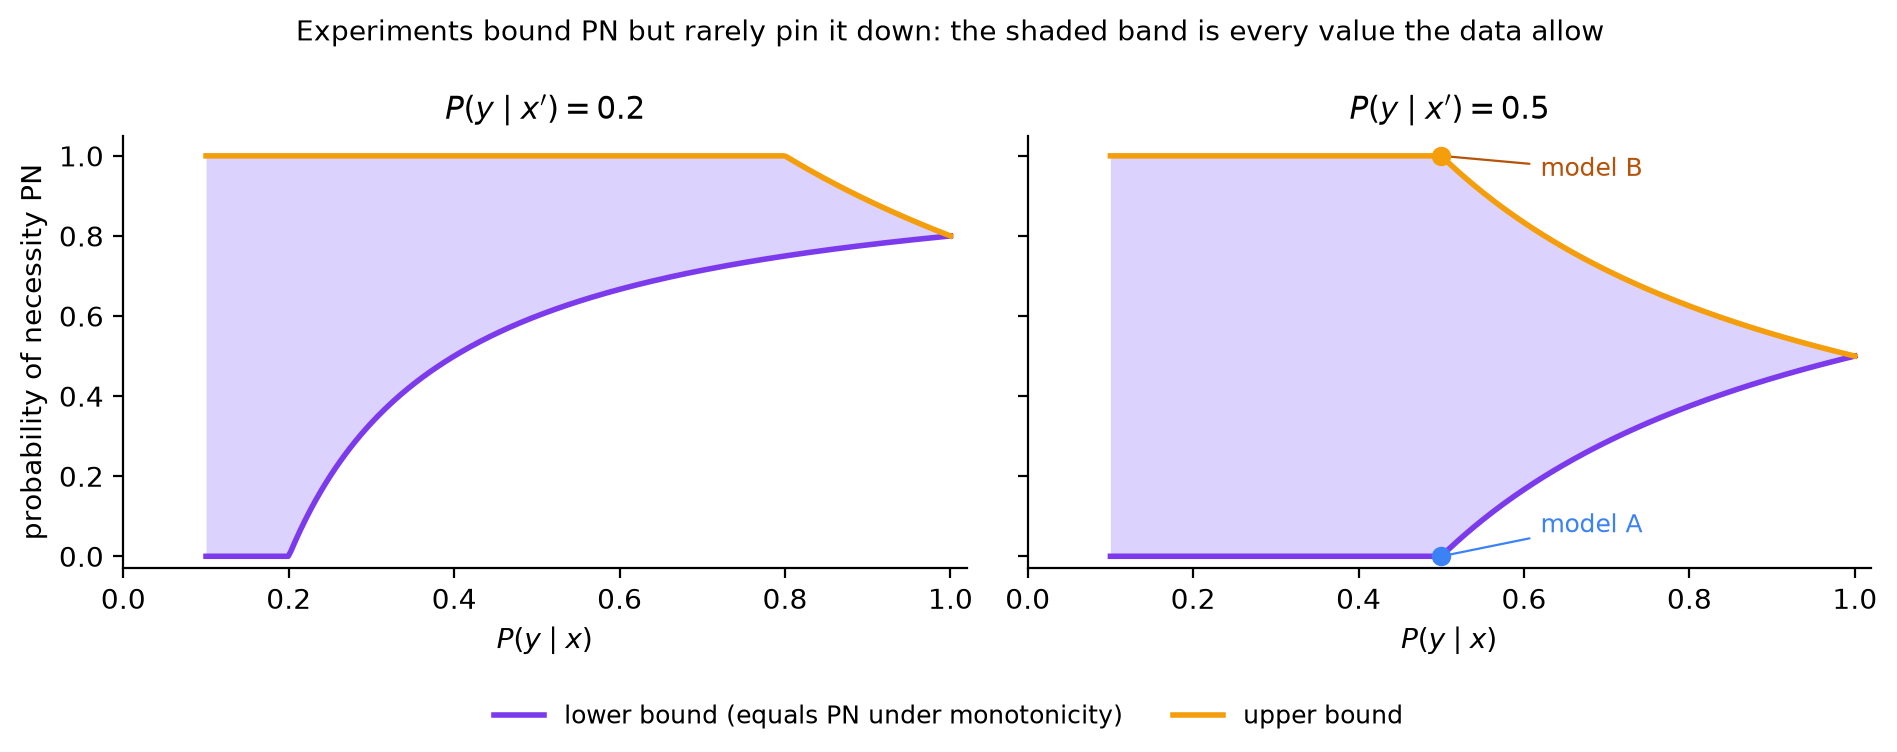

In [3]:
_show_mpl(_lessonfigs.pn_bounds())

*The band between the curves is every value of PN consistent with a randomized trial, for two values of $P(y \mid x')$. For the two models of the proposition, $P(y \mid x) = P(y \mid x') = 1/2$, and the band is the whole interval $[0, 1]$: model A sits at the bottom and model B at the top.*

## Compute it

A structural model is a function from background values to modeled values, with an optional action. Abduction inverts the mechanisms at the evidence; action and prediction rerun the model with the same background values. The last part checks the partial-evidence result [](#eq-l4-09-posterior) by simulation: keep only simulated worlds whose $Y$ is close to 5, then set $X$ to 0 in those worlds.


In [4]:
import numpy as np

# The running model: X := U_X,  Y := 2X + U_Y
def scm(u, do=None):
    # solve the model for background values u; do={'X': x} replaces the mechanism of X
    do = do or {}
    x = do.get('X', u['UX'])
    y = do.get('Y', 2 * x + u['UY'])
    return {'X': x, 'Y': y}

# 1 abduction: invert each mechanism at the evidence X = 1, Y = 5
x_obs, y_obs = 1, 5
u = {'UX': x_obs, 'UY': y_obs - 2 * x_obs}
print('abduction      ', u)
# 2 action and 3 prediction: same u, edited model
print('factual        ', scm(u))
print('counterfactual ', scm(u, do={'X': 0}))

# Worked example: Z := U_Z,  X := Z + U_X,  Y := 2X + Z + U_Y, evidence Z=1, X=2, Y=7
def scm3(u, do=None):
    do = do or {}
    z = do.get('Z', u['UZ'])
    x = do.get('X', z + u['UX'])
    y = do.get('Y', 2 * x + z + u['UY'])
    return {'Z': z, 'X': x, 'Y': y}

z, x, y = 1, 2, 7
u3 = {'UZ': z, 'UX': x - z, 'UY': y - 2 * x - z}
print('abduction      ', u3)
print('had X been 0   ', scm3(u3, {'X': 0}))
print('had Z been 0   ', scm3(u3, {'Z': 0}))

# Partial evidence: only Y = 5 is seen. Exact Gaussian conditioning, then a simulation check.
var_y, cov = 2 ** 2 * 1 + 1, 1.0                  # Var(Y) = 5, Cov(U_Y, Y) = 1
mean, var = 1 + cov / var_y * (5 - 1), 1 - cov ** 2 / var_y
print('exact      Y_{X=0} | Y=5 ~ N(%.2f, %.2f)' % (mean, var))
rng = np.random.default_rng(0)
ux, uy = rng.normal(0, 1, 2_000_000), rng.normal(1, 1, 2_000_000)
keep = np.abs(2 * ux + uy - 5) < 0.05             # worlds whose Y is (nearly) 5
y0 = 2 * 0 + uy[keep]                             # same noise, X set to 0
print('simulated  mean %.3f, var %.3f from %d worlds' % (y0.mean(), y0.var(), keep.sum()))
print('interventional E[Y | do(X=0)] = %.3f' % (2 * 0 + uy).mean())

abduction       {'UX': 1, 'UY': 3}
factual         {'X': 1, 'Y': 5}
counterfactual  {'X': 0, 'Y': 3}
abduction       {'UZ': 1, 'UX': 1, 'UY': 2}
had X been 0    {'Z': 1, 'X': 0, 'Y': 3}
had Z been 0    {'Z': 0, 'X': 1, 'Y': 4}
exact      Y_{X=0} | Y=5 ~ N(1.80, 0.80)
simulated  mean 1.804, var 0.798 from 7141 worlds
interventional E[Y | do(X=0)] = 0.999


The two models of the proposition, enumerated exactly with fractions, and the bounds [](#eq-l4-09-bounds). The last line sweeps every joint law of $(Y_1, Y_0)$ with the margins of a trial and shows that PN fills the whole interval.


In [5]:
from fractions import Fraction
from itertools import product

models = {'A  Y := U      ': lambda x, u: u,
          'B  Y := X xor U': lambda x, u: x ^ u}
for name, f in models.items():
    joint = {}
    for x, u in product((0, 1), (0, 1)):           # X and U independent fair coins
        joint[(x, f(x, u))] = joint.get((x, f(x, u)), 0) + Fraction(1, 4)
    do = [sum(Fraction(1, 2) * f(x, u) for u in (0, 1)) for x in (0, 1)]
    post = [u for u in (0, 1) if f(1, u) == 1]      # abduction for the unit with X=1, Y=1
    pn = Fraction(sum(1 for u in post if f(0, u) == 0), len(post))
    print(name, '| P(X,Y):', {k: str(v) for k, v in sorted(joint.items())},
          '| P(Y=1|do(X=x)):', [str(d) for d in do], '| PN =', pn)

def pn_bounds(p_y_x, p_y_xp):
    # bounds on PN when X is exogenous (for example randomized)
    lo, hi = max(0.0, (p_y_x - p_y_xp) / p_y_x), min(1.0, (1 - p_y_xp) / p_y_x)
    return round(lo, 6), round(hi, 6)

print('bounds, P(y|x) = 0.5 and P(y|xp) = 0.5:', pn_bounds(0.5, 0.5))
print('bounds, P(y|x) = 0.8 and P(y|xp) = 0.4:', pn_bounds(0.8, 0.4))
# every coupling of (Y_1, Y_0) with these margins: PN = P(Y_1=1, Y_0=0) / P(Y_1=1)
p1, p0 = 0.8, 0.4
t = np.linspace(max(0, p1 - p0), min(p1, 1 - p0), 5)
print('PN over all couplings:', np.round(t / p1, 3))

A  Y := U       | P(X,Y): {(0, 0): '1/4', (0, 1): '1/4', (1, 0): '1/4', (1, 1): '1/4'} | P(Y=1|do(X=x)): ['1/2', '1/2'] | PN = 0
B  Y := X xor U | P(X,Y): {(0, 0): '1/4', (0, 1): '1/4', (1, 0): '1/4', (1, 1): '1/4'} | P(Y=1|do(X=x)): ['1/2', '1/2'] | PN = 1
bounds, P(y|x) = 0.5 and P(y|xp) = 0.5: (0.0, 1.0)
bounds, P(y|x) = 0.8 and P(y|xp) = 0.4: (0.5, 0.75)
PN over all couplings: [0.5   0.562 0.625 0.688 0.75 ]


:::{prf:remark} An edited input is not a counterfactual
Changing one input of a fitted predictor and reading off the new prediction skips two steps. It skips abduction, so it forgets what the evidence said about this unit's background. It also skips the downstream mechanisms: in the worked example, changing $Z$ also changes $X$. A counterfactual explanation of a prediction is only as causal as the structural model behind it.
:::

## Worked example

:::{admonition} A counterfactual that moves a mediator
:class: tip

In the model $Z := U_Z$, $X := Z + U_X$, $Y := 2X + Z + U_Y$, a unit is observed with $Z = 1$, $X = 2$, $Y = 7$. What would $Y$ have been (a) had $X$ been 0, and (b) had $Z$ been 0?

1. Abduction, one mechanism at a time: $u_Z = 1$; $u_X = X - Z = 2 - 1 = 1$; $u_Y = Y - 2X - Z = 7 - 4 - 1 = 2$.
2. (a) Action $X := 0$, keeping $Z := U_Z$ and the mechanism of $Y$. Prediction: $Z = 1$, $Y = 2 \cdot 0 + 1 + 2 = 3$.
3. (b) Action $Z := 0$. Now $X$ is downstream of $Z$, so its mechanism recomputes it: $X = 0 + u_X = 1$. Prediction: $Y = 2 \cdot 1 + 0 + 2 = 4$.
4. Check against the shortcut of editing $Z$ only inside the equation for $Y$: $2 \cdot 2 + 0 + 2 = 6$. That number is wrong because it holds $X$ at its factual value 2, which the action on $Z$ would have changed.

**Result.** $Y_{X=0} = 3$ and $Y_{Z=0} = 4$ for this unit. The code above reproduces both.
:::

## Exercises

**1. (Core)** Use the model $Y := 3X + U$. A unit is observed with $X = 2$, $Y = 10$. Under this exact structural model, what would $Y$ have been had $X$ been 0?

:::{dropdown} Solution
Abduction: $u = 10 - 3 \cdot 2 = 4$. Action: $X := 0$. Prediction with the same $u$: $Y = 3 \cdot 0 + 4 = 4$.
:::

**2. (Core)** In the running model [](#eq-l4-09-scm), a second unit is observed with $X = 0$ and $Y = 0.5$. What would its $Y$ have been had $X$ been 1? Compare with $E[Y \mid do(X = 1)]$.

:::{dropdown} Solution
Abduction: $u_Y = 0.5 - 0 = 0.5$. Prediction: $Y_{X=1} = 2 \cdot 1 + 0.5 = 2.5$. The interventional mean is $E[Y \mid do(X=1)] = 2 + E[U_Y] = 3$. This unit sits below average because its $u_Y$ is below the mean 1.
:::

**3. (Stretch)** In the running model only $Y = 3$ is observed. Find the distribution of $Y_{X=0}$ and the value of $E[Y_{X=1} \mid Y = 3]$.

:::{dropdown} Solution
$Y_{X=0} = U_Y$ and, by [](#eq-l4-09-posterior), $U_Y \mid Y = 3 \sim \mathcal{N}(1 + \tfrac{1}{5}(3 - 1),\ 0.8) = \mathcal{N}(1.4,\ 0.8)$. Since $Y_{X=1} = 2 + U_Y$, $E[Y_{X=1} \mid Y = 3] = 2 + 1.4 = 3.4$.
:::

**4. (Stretch)** Take $Y := X \cdot U$ with $U$ equal to 1 or 3 with probability $1/2$ each, and $X$ randomized. (a) Compute $E[Y \mid do(X = 2)] - E[Y \mid do(X = 1)]$. (b) A unit is seen with $X = 1$, $Y = 3$. What would $Y$ have been with $X = 2$, and what is this unit's effect of moving from 1 to 2? (c) Why does the formula of the additive noise proposition not apply?

:::{dropdown} Solution
(a) $E[Y \mid do(X = x)] = x\,E[U] = 2x$, so the difference is $4 - 2 = 2$. (b) Abduction: $u = Y/X = 3$. Prediction: $Y_{X=2} = 2 \cdot 3 = 6$, so this unit's effect is $6 - 3 = 3$, larger than the average effect 2. (c) The noise multiplies $X$ instead of being added, so the effect $x' u - x u$ depends on $u$ and differs across units.
:::

**5. (Challenge)** A randomized trial finds $P(y \mid x) = 0.8$ and $P(y \mid x') = 0.4$. (a) Bound PN with [](#eq-l4-09-bounds). (b) Write down a joint law of $(Y_1, Y_0)$ with these margins that attains each end. (c) What is PN if no unit is harmed by treatment?

:::{dropdown} Solution
(a) Lower: $(0.8 - 0.4)/0.8 = 0.5$. Upper: $\min\{1, 0.6/0.8\} = 0.75$. So $0.5 \le \mathrm{PN} \le 0.75$. (b) With $t = P(Y_1 = 1, Y_0 = 0)$, the cells are $P(1,0) = t$, $P(1,1) = 0.8 - t$, $P(0,1) = t - 0.4$, $P(0,0) = 0.6 - t$. Lower end: $t = 0.4$ gives cells $0.4, 0.4, 0, 0.2$ and $\mathrm{PN} = 0.4/0.8 = 0.5$. Upper end: $t = 0.6$ gives cells $0.6, 0.2, 0.2, 0$ and $\mathrm{PN} = 0.6/0.8 = 0.75$. (c) Monotonicity empties the cell $P(0, 1)$, which forces $t = 0.4$ and $\mathrm{PN} = 0.5$.
:::

## Check your understanding

**1. Which step of the counterfactual procedure uses the factual evidence to update the background variables?**

- **A.** Randomization
- **B.** Abduction
- **C.** Action
- **D.** Prediction

:::{dropdown} Show the answer
**B. Abduction**

Abduction computes $P(u \mid e)$ in the original model. Action then replaces a mechanism, and prediction evaluates the edited model with the updated background distribution.
:::

**2. In the model $X := U_X$, $Y := 2X + U_Y$, a unit is seen with $X = 1$ and $Y = 5$. What would its $Y$ have been had $X$ been 0?**

- **A.** 1.8
- **B.** 5
- **C.** 1
- **D.** 3

:::{dropdown} Show the answer
**D. 3**

Abduction gives $u_Y = 5 - 2 = 3$, and prediction gives $2 \cdot 0 + 3 = 3$. The value 1 is the population mean $E[Y \mid do(X=0)]$, and 1.8 is the posterior mean when only $Y = 5$ is known.
:::

**3. Two structural models agree on $P(x, y)$ and on $P(y \mid do(x))$ for every $x$. What follows about $P(Y_0 = 0 \mid X = 1, Y = 1)$?**

- **A.** It equals $P(Y = 0 \mid do(X = 0))$
- **B.** It can still differ between the two models
- **C.** It is always one half
- **D.** It must be the same in both models

:::{dropdown} Show the answer
**B. It can still differ between the two models**

Counterfactuals sit on the third rung. The models $Y := U$ and $Y := X \oplus U$ agree on every observational and interventional quantity but give 0 and 1 for this probability.
:::

**4. In the model $X := U$, $Y := 2X + U$ with $P(U = 1) = P(U = 0) = 1/2$, what is $E[Y \mid do(X = 1)]$?** *(Review of [L4-01](#lesson-l4-01))*

- **A.** 0.5
- **B.** 2
- **C.** 3
- **D.** 2.5

:::{dropdown} Show the answer
**D. 2.5**

The action replaces $X := U$ by $X := 1$ and keeps the law of $U$, so $E[Y \mid do(X=1)] = 2 + E[U] = 2.5$. Observing $X = 1$ instead reveals $U = 1$ and gives 3.
:::

## Common misconceptions

- **"A counterfactual is just $E[Y \mid do(X = x)]$."** The interventional mean averages over the whole population's background variables. A counterfactual first conditions on what was seen about a unit, which can move the answer far from the average: 3 instead of 1 in the running model.
- **"To get a counterfactual, change one input of a trained predictor and read the new output."** That skips abduction and ignores the mechanisms downstream of the changed variable. It answers a question about the predictor, not about the world, unless the predictor is a correct structural model.
- **"If a randomized trial shows no average effect, the treatment affected nobody."** Model B, $Y := X \oplus U$, has zero average effect while every unit is affected, half helped and half harmed. Averages can hide effects that cancel.

:::{caution} Scope and limits
Every counterfactual here is relative to a fully specified structural model: the mechanisms, the joint law of the background variables (independent in the running model), and acyclicity. These are assumptions, and in general neither observational nor experimental data can confirm them. The Gaussian posterior uses the assumed normal noise; a different noise law with the same mean and variance gives a different answer. The bounds on PN assume binary variables and an exogenous treatment. The tutoring story is an illustration, and its numbers are not estimates from any study.
:::

:::{seealso} Where this leads
Counterfactuals return in [L4-10](#lesson-l4-10), where counterfactual fairness compares a unit's prediction in its own world and in a world with a protected attribute changed. Nested counterfactuals define natural direct and indirect effects in mediation analysis [@pearlcausality]. Level 6 asks whether, and how, abduction and counterfactuals can be defined for quantum causal models, where background variables cannot be assumed to have definite values.
:::

:::{dropdown} For instructors

**Why this lesson.** Students who have learned interventions often think counterfactuals are a notational variant of them. The two-model proposition shows that the third rung carries strictly more information, and the three-step procedure gives a concrete algorithm that works in any structural model [@pearl; @pearlcausality; @bareinboim].

**Teaching notes.**

- Have students compute the three numbers 1, 1 and 3 for seeing, doing and imagining before showing the animation; the gap between 1 and 3 motivates abduction.
- Emphasize that abduction uses the original model. Ask what goes wrong if one tries to explain the evidence $X = 1$ with the mechanism $X := 0$.
- Use the twin network diagram to make the shared background variables explicit, then draw the twin network for the worked example with three variables.
- Let students explore the interactive at $y = 1$, where the evidence matches the prior mean and abduction learns nothing about $u_Y$ beyond narrowing its spread.

**Assessment.** The worked example and the stretch exercise on partial evidence test the full procedure; the challenge exercise tests whether students can move between counterfactual probabilities and joint laws of potential outcomes. The third check question tests the rung distinction.

**Going further.** Derive the twin network for a model with a mediator and compute a natural direct effect. Read the treatment of counterfactuals and the probabilities of causation in Pearl's monograph [@pearlcausality], and the discussion of counterfactuals in structural models in Peters, Janzing and Schölkopf [@peters].

:::

## References

This lesson draws on [@pearl; @pearlcausality; @peters; @bareinboim; @hernan; @tianpearl2000].

**Further reading.**

- [@pearlcausality]: The monograph's chapters on counterfactuals and on the probability of causation develop the three-step procedure and the PN bounds in full.
- [@peters]: Treats counterfactuals within structural causal models and contrasts them with interventional distributions.
- [@hernan]: The potential-outcomes view of individual and average effects, and why individual effects are rarely identified.

**Next:** [L4-10 · Causal machine learning, transport, and fairness](#lesson-l4-10)
